# 07 — Multi-Dataset Training on Native Zeek `conn.log` Features

**Goal:** Test whether training on multiple Zeek datasets improves generalization to **unseen future captures** (2025) without hurting performance on `TON_IoT`.

**Features used (11 native Zeek `conn.log` columns — no IPs, no ports, no TTL):**
- Categorical (3): `proto`, `service`, `conn_state`
- Numeric (8): `duration`, `orig_bytes`, `resp_bytes`, `missed_bytes`, `orig_pkts`, `orig_ip_bytes`, `resp_pkts`, `resp_ip_bytes`

**Experiment (adding one dataset at a time):**
- **Run A:** `TON_IoT` only
- **Run B:** `TON_IoT` + `UWF-ZeekData24`
- **Run C:** `TON_IoT` + `UWF-ZeekData24` + `UWF-ZeekDataFall24-2`

**Evaluated on 3 test sets:**
1. Held-out `TON_IoT` test split (20%, deduplicated)
2. Unseen future capture: `UWF-ZeekDataSum25-1` (Summer 2025)
3. Unseen future capture: `UWF-ZeekDataSum25-2` (Summer 2025)

In [1]:
from pathlib import Path
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SEED = 42

CAT_COLS = ["proto", "service", "conn_state"]
NUM_COLS = [
    "duration", "orig_bytes", "resp_bytes", "missed_bytes",
    "orig_pkts", "orig_ip_bytes", "resp_pkts", "resp_ip_bytes",
]
FEAT_COLS = CAT_COLS + NUM_COLS


def normalize_schema(df: pd.DataFrame) -> pd.DataFrame:
    """Ensure identical dtypes and missing-value conventions across datasets."""
    out = df.copy()
    for c in CAT_COLS:
        out[c] = out[c].fillna("-").astype(object)
    for c in NUM_COLS:
        out[c] = out[c].fillna(0.0).astype(float)
    return out


def load_ton_iot() -> pd.DataFrame:
    """Load TON_IoT network CSV and rename columns to official Zeek conn.log names."""
    rename_map = {
        "src_bytes": "orig_bytes",
        "dst_bytes": "resp_bytes",
        "src_pkts": "orig_pkts",
        "src_ip_bytes": "orig_ip_bytes",
        "dst_pkts": "resp_pkts",
        "dst_ip_bytes": "resp_ip_bytes",
        "type": "attack_type",
    }
    df = pd.read_csv(ROOT / "datasets/ton_iot/train_test_network.csv").rename(columns=rename_map)
    df["label"] = df["label"].astype(int)
    df["attack_type"] = df["attack_type"].astype(str)
    return normalize_schema(df[FEAT_COLS + ["label", "attack_type"]])


def load_uwf(dataset_name: str) -> pd.DataFrame:
    """Load a UWF-ZeekData Parquet dataset and drop multi-tactic Duplicate rows."""
    pattern = str(ROOT / f"datasets/uwf_zeek/{dataset_name}/parquet/*/*.parquet")
    files = sorted(glob.glob(pattern))
    cols = FEAT_COLS + ["label_binary", "label_tactic"]
    df = pd.concat([pd.read_parquet(f, columns=cols) for f in files], ignore_index=True)
    df = df[df["label_binary"] != "Duplicate"].copy()
    df["label"] = (df["label_binary"] == "True").astype(int)
    df["attack_type"] = df["label_tactic"].astype(str)
    return normalize_schema(df[FEAT_COLS + ["label", "attack_type"]])


def make_balanced_chunk(df: pd.DataFrame, max_per_class: int = 40_000, seed: int = SEED) -> pd.DataFrame:
    """Deduplicate and sample a balanced benign/attack chunk stratified across attack types.

    Why: prevents huge datasets (or one giant attack campaign like Port 4848) from
    drowning out smaller datasets and rarer attack tactics.
    """
    dedup = df.drop_duplicates(subset=FEAT_COLS + ["label"]).copy()
    benign = dedup[dedup["label"] == 0]
    attack = dedup[dedup["label"] == 1]

    benign_s = benign.sample(n=min(len(benign), max_per_class), random_state=seed)

    # Stratified cap across attack types so rare tactics stay represented
    if len(attack) <= max_per_class:
        attack_s = attack
    else:
        parts = []
        types = sorted(attack["attack_type"].unique())
        quota = max(1, max_per_class // len(types))
        remaining = max_per_class
        # Take smaller classes in full first, then cap larger ones
        counts = attack["attack_type"].value_counts().sort_values()
        for i, (t, cnt) in enumerate(counts.items()):
            left = len(counts) - i
            take = min(cnt, max(quota, remaining // left))
            parts.append(attack[attack["attack_type"] == t].sample(n=take, random_state=seed))
            remaining -= take
        attack_s = pd.concat(parts, ignore_index=True)

    return pd.concat([benign_s, attack_s], ignore_index=True).sample(frac=1.0, random_state=seed)


In [2]:
# 1. Load TON_IoT and create a deduplicated 80/20 train/test split
ton_raw = load_ton_iot()
ton_dedup = ton_raw.drop_duplicates(subset=FEAT_COLS + ["label"]).copy()
ton_train, ton_test = train_test_split(
    ton_dedup, test_size=0.2, random_state=SEED, stratify=ton_dedup["attack_type"]
)

# 2. Load 2024 UWF training datasets as balanced chunks
uwf24_train = make_balanced_chunk(load_uwf("UWF-ZeekData24"), max_per_class=40_000)
uwf_fall24_train = make_balanced_chunk(load_uwf("UWF-ZeekDataFall24-2"), max_per_class=40_000)

# 3. Load completely unseen 2025 test datasets (full, not subsampled)
sum25_1_test = load_uwf("UWF-ZeekDataSum25-1")
sum25_2_test = load_uwf("UWF-ZeekDataSum25-2")

summary = pd.DataFrame([
    {"split": "ton_train (train)", "rows": len(ton_train), "benign": (ton_train["label"] == 0).sum(), "attack": (ton_train["label"] == 1).sum()},
    {"split": "uwf24_train (train chunk)", "rows": len(uwf24_train), "benign": (uwf24_train["label"] == 0).sum(), "attack": (uwf24_train["label"] == 1).sum()},
    {"split": "uwf_fall24_train (train chunk)", "rows": len(uwf_fall24_train), "benign": (uwf_fall24_train["label"] == 0).sum(), "attack": (uwf_fall24_train["label"] == 1).sum()},
    {"split": "ton_test (held-out)", "rows": len(ton_test), "benign": (ton_test["label"] == 0).sum(), "attack": (ton_test["label"] == 1).sum()},
    {"split": "UWF-Sum25-1 (unseen 2025)", "rows": len(sum25_1_test), "benign": (sum25_1_test["label"] == 0).sum(), "attack": (sum25_1_test["label"] == 1).sum()},
    {"split": "UWF-Sum25-2 (unseen 2025)", "rows": len(sum25_2_test), "benign": (sum25_2_test["label"] == 0).sum(), "attack": (sum25_2_test["label"] == 1).sum()},
])
summary

,split,rows,benign,attack
0,ton_train (train),73975,18468,55507
1,uwf24_train (train chunk),80000,40000,40000
2,uwf_fall24_train (train chunk),53718,40000,13718
3,ton_test (held-out),18494,4618,13876
4,UWF-Sum25-1 (unseen 2025),1149977,576759,573218
5,UWF-Sum25-2 (unseen 2025),1868679,934226,934453


In [3]:
def build_model() -> Pipeline:
    pre = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
        ("num", "passthrough", NUM_COLS),
    ])
    clf = HistGradientBoostingClassifier(random_state=SEED, class_weight="balanced")
    return Pipeline([("pre", pre), ("clf", clf)])


runs = {
    "Run A: TON_IoT only": ton_train,
    "Run B: TON + UWF-24": pd.concat([ton_train, uwf24_train], ignore_index=True),
    "Run C: TON + UWF-24 + Fall24-2": pd.concat([ton_train, uwf24_train, uwf_fall24_train], ignore_index=True),
}

test_sets = {
    "TON_IoT (held-out)": ton_test,
    "UWF-Sum25-1 (unseen 2025)": sum25_1_test,
    "UWF-Sum25-2 (unseen 2025)": sum25_2_test,
}

fitted_models = {}
rows = []

for run_name, train_df in runs.items():
    model = build_model()
    model.fit(train_df[FEAT_COLS], train_df["label"].to_numpy(dtype=int))
    fitted_models[run_name] = model

    for test_name, test_df in test_sets.items():
        y_true = test_df["label"].to_numpy(dtype=int)
        y_pred = model.predict(test_df[FEAT_COLS])
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
        rows.append({
            "Run": run_name,
            "Test Set": test_name,
            "F1": round(f1_score(y_true, y_pred), 4),
            "Precision": round(precision_score(y_true, y_pred), 4),
            "Recall": round(recall_score(y_true, y_pred), 4),
            "FPR": round(fp / (fp + tn), 4),
        })

results_df = pd.DataFrame(rows)
results_df

,Run,Test Set,F1,Precision,Recall,FPR
0,Run A: TON_IoT only,TON_IoT (held-out),0.9962,0.9975,0.9949,0.0074
1,Run A: TON_IoT only,UWF-Sum25-1 (unseen 2025),0.7963,0.9994,0.6618,0.0004
2,Run A: TON_IoT only,UWF-Sum25-2 (unseen 2025),0.5815,0.9861,0.4124,0.0058
3,Run B: TON + UWF-24,TON_IoT (held-out),0.9905,0.9966,0.9845,0.0102
4,Run B: TON + UWF-24,UWF-Sum25-1 (unseen 2025),0.7444,0.9997,0.5930,0.0002
5,Run B: TON + UWF-24,UWF-Sum25-2 (unseen 2025),0.5829,0.9938,0.4124,0.0026
6,Run C: TON + UWF-24 + Fall24-2,TON_IoT (held-out),0.9862,0.9949,0.9777,0.0152
7,Run C: TON + UWF-24 + Fall24-2,UWF-Sum25-1 (unseen 2025),0.9942,0.9999,0.9886,0.0001
8,Run C: TON + UWF-24 + Fall24-2,UWF-Sum25-2 (unseen 2025),0.9989,0.9978,1.0000,0.0022


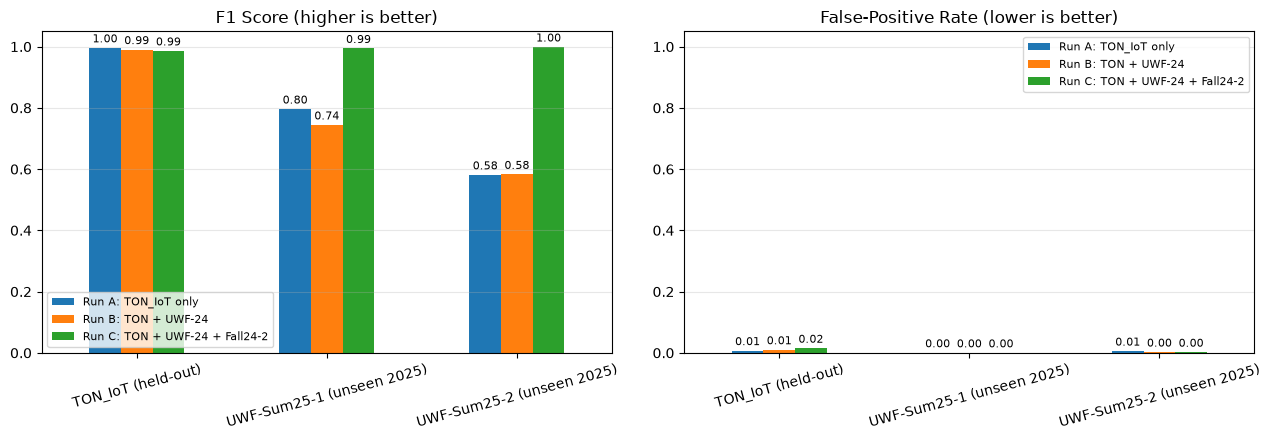

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, metric, title in [
    (axes[0], "F1", "F1 Score (higher is better)"),
    (axes[1], "FPR", "False-Positive Rate (lower is better)"),
]:
    piv = results_df.pivot(index="Test Set", columns="Run", values=metric)
    piv = piv.loc[list(test_sets.keys()), list(runs.keys())]
    piv.plot(kind="bar", ax=ax, rot=15)
    ax.set_title(title)
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("")
    ax.grid(axis="y", alpha=0.3)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", fontsize=8, padding=2)

axes[0].legend(loc="lower left", fontsize=8)
axes[1].legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

In [5]:
# Compare Run A vs Run C per MITRE tactic on the unseen 2025 datasets
for test_name in ["UWF-Sum25-1 (unseen 2025)", "UWF-Sum25-2 (unseen 2025)"]:
    df_t = test_sets[test_name]
    tactics = df_t["attack_type"].to_numpy(dtype=str)
    pred_a = fitted_models["Run A: TON_IoT only"].predict(df_t[FEAT_COLS])
    pred_c = fitted_models["Run C: TON + UWF-24 + Fall24-2"].predict(df_t[FEAT_COLS])

    tactic_rows = []
    for tac in sorted(np.unique(tactics)):
        m = tactics == tac
        if tac == "none":
            tactic_rows.append({
                "Tactic": "none (benign FPR)",
                "Count": int(m.sum()),
                "Run A": round(float((pred_a[m] == 1).mean()), 4),
                "Run C": round(float((pred_c[m] == 1).mean()), 4),
            })
        else:
            tactic_rows.append({
                "Tactic": tac,
                "Count": int(m.sum()),
                "Run A": round(float((pred_a[m] == 1).mean()), 4),
                "Run C": round(float((pred_c[m] == 1).mean()), 4),
            })
    print(f"\n=== {test_name} ===")
    display(pd.DataFrame(tactic_rows))


=== UWF-Sum25-1 (unseen 2025) ===


,Tactic,Count,Run A,Run C
0,Defense Evasion,3532,0.4929,0.9921
1,Discovery,1099,0.4177,1.0000
2,Initial Access,1,1.0000,1.0000
3,Lateral Movement,326,0.9939,0.9939
4,Reconnaissance,568260,0.6631,0.9886
5,none (benign FPR),576759,0.0004,0.0001



=== UWF-Sum25-2 (unseen 2025) ===


,Tactic,Count,Run A,Run C
0,Discovery,477271,0.4106,1.0000
1,Reconnaissance,457182,0.4142,1.0000
2,none (benign FPR),934226,0.0058,0.0022


### Key Takeaways
- **Multi-dataset training works:** Adding `UWF-ZeekData24` + `UWF-ZeekDataFall24-2` to `TON_IoT` lifted unseen 2025 `UWF-Sum25-1/2` F1 from **0.58–0.80 → 0.994–0.999** with **≤0.22% FPR**.
- **Limitation:** Single isolated flows still struggle to generalize across unrelated networks, and `UWF` benign traffic is mostly idle DNS (0-byte TCP).
- **Next (`08`):** Test 60-second per-host behavioral windows instead of isolated single flows.